In [1]:
import os
import sys
import pickle
import glob

import pandas as pd
import sqlite3
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.cluster import AgglomerativeClustering, HDBSCAN
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity

%load_ext autoreload
%autoreload 2

pd.set_option('display.width', 1000)
pd.set_option('max_colwidth', 1000)

In [2]:
embedding_pths = sorted(glob.glob("embeddings/*"))
len(embedding_pths)

9634

In [3]:
avg_embeddings = []
for idx in range(len(embedding_pths)):
    with open(embedding_pths[idx], "rb") as f:
        embeddings = np.load(f)
    
    if embeddings.shape[0] == 0:
        print(embedding_pths[idx])
    else:
        avg_embeddings.append(np.mean(embeddings, axis=0))

print(len(avg_embeddings))

9634


In [4]:
mtx_sclearn_dist = cosine_distances(np.array(avg_embeddings).reshape(-1, 768))

In [5]:
clusters = AgglomerativeClustering(n_clusters=None, metric="precomputed", distance_threshold=0.4, linkage="average").fit(mtx_sclearn_dist)
np.unique(clusters.labels_).shape

(456,)

{'whiskers': [<matplotlib.lines.Line2D at 0x7c13f7031960>,
 'caps': [<matplotlib.lines.Line2D at 0x7c13f7031ea0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7c13f70316c0>],
 'medians': [<matplotlib.lines.Line2D at 0x7c13f70323e0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7c13f7032680>],
 'means': []}

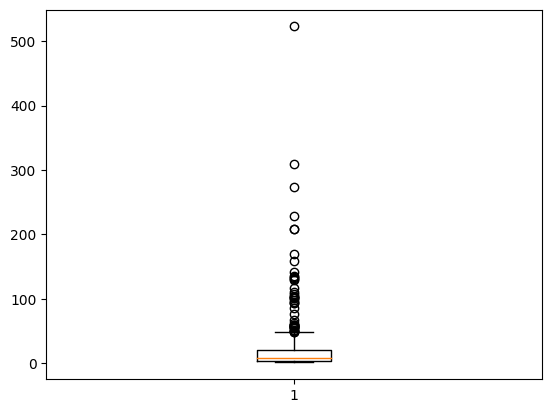

In [6]:
labels, counts = np.unique(clusters.labels_, return_counts=True)
plt.boxplot(counts)

In [7]:
cl_similar = AgglomerativeClustering(n_clusters=None, metric="precomputed", distance_threshold=0.01, linkage="average").fit(mtx_sclearn_dist)
np.unique(cl_similar.labels_).shape

(7636,)

In [8]:
labels, counts = np.unique(cl_similar.labels_, return_counts=True)

In [9]:
counts.shape, counts[counts > 1].shape

((7636,), (1328,))

In [10]:
counts[counts == 3]

array([3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3])

In [11]:
labels[counts == 3]

array([   0,   15,   17,   19,   22,   24,   27,   29,   38,   43,   44,
         48,   52,   54,   55,   58,   59,   63,   67,   69,   90,   95,
         96,  103,  108,  109,  111,  112,  118,  134,  152,  162,  164,
        166,  170,  174,  186,  188,  200,  218,  229,  230,  234,  243,
        261,  269,  306,  313,  323,  326,  331,  337,  353,  359,  376,
        378,  384,  392,  405,  410,  413,  422,  425,  437,  448,  455,
        462,  473,  474,  506,  538,  602,  603,  663,  675,  826,  840,
        934,  936,  947, 1050, 1059, 1354, 1373, 1471, 1520, 1587, 1592,
       1628, 1673, 1754, 1803, 1818, 1832, 1903, 2520, 3794])

In [12]:
labels[counts == 2]

array([   1,    2,    4, ..., 6634, 7365, 7498])

In [13]:
np.array(embedding_pths)[cl_similar.labels_ == 0]

array(['embeddings/PG1_H300_PIR_Cross_Angles_W_23_12_36_24_2016',
       'embeddings/PG1_H300_PIR_Cross_Angles_W_23_12_39_40_2016',
       'embeddings/PG1_H300_PIR_Cross_Angles_W_23_12_41_08_2016'],
      dtype='<U86')

In [14]:
np.array(embedding_pths)[cl_similar.labels_ == 15]

array(['embeddings/PG1_H255_HD_PG_stitch170712_08_1499864442',
       'embeddings/PG1_H255_HD_stitch150cm_PG_170712_07_VB_1499863601',
       'embeddings/PG1_H255_HD_stitch150cm_PG_170712_08_VB_1499864442'],
      dtype='<U86')

In [15]:
np.array(embedding_pths)[cl0.labels_ == 1]

NameError: name 'cl0' is not defined

In [ ]:
np.array(embedding_pths)[cl0.labels_ == 4]

array(['embeddings/PG1_H255_PIR_T25_InOut_OfficePG_Eyal_03_10_00_23_2016',
       'embeddings/PG1_H255_PIR_T25_InOut_OfficePG_Eyal_03_10_01_40_2016',
       'embeddings/PG1_H255_PIR_T25_InOut_OfficePG_Eyal_03_10_02_22_2016',
       'embeddings/PG1_H255_PIR_T25_InOut_OfficePG_Eyal_03_10_05_59_2016',
       'embeddings/PG1_H255_PIR_T25_InOut_OfficePG_Eyal_03_10_06_40_2016',
       'embeddings/PG1_H255_PIR_T25_InOut_OfficePG_Eyal_03_10_07_20_2016',
       'embeddings/PG1_H255_PIR_T25_InOut_OfficePG_Eyal_03_10_08_34_2016',
       'embeddings/PG1_H255_PIR_T25_InOut_OfficePG_Eyal_03_10_09_56_2016',
       'embeddings/PG1_H255_PIR_T25_InOut_OfficePG_Eyal_03_10_10_56_2016',
       'embeddings/PG1_H255_PIR_T25_InOut_OfficePG_Eyal_03_10_12_17_2016',
       'embeddings/PG1_H255_PIR_T25_InOut_OfficePG_Eyal_03_10_13_02_2016',
       'embeddings/PG1_H255_PIR_T25_InOut_OfficePG_Eyal_03_10_13_37_2016',
       'embeddings/PG1_H255_PIR_T25_InOut_OfficePG_Eyal_03_10_14_24_2016',
       'embeddings/PG1_H2

In [ ]:
df = pd.read_csv("../seq_files.csv")
df.head()

,seq_name,seq_path,avi_path,frame_h,frame_w,camera_type,altitude
0,Noise_1_enter_exit_NoSw_28_16_15_11_2015.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/Occupancy/OCS_people_counting_H253_B_PIRar/Noise_1_enter_exit_NoSw_28_16_15_11_2015.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/Occupancy/OCS_people_counting_H253_B_PIRar/Noise_1_enter_exit_NoSw_28_16_15_11_2015.avi,720.0,1280.0,NaN,253
1,PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_1509285767.avi.seq,/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev2_high_height_Q/PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_1509285767.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_PIR2chnl/PG1_AlgoDev2_high_height_Q/PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_1509285767.avi,960.0,1280.0,SunPlus_PG_Camera,660
2,PG1_DL_H300_Walking_NY_St1707_1500538480.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_DL/PG1_DL_training_POS10_Walking/PG1_DL_H300_Walking_NY_St1707_1500538480.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_DL/PG1_DL_training_POS10_Walking/PG1_DL_H300_Walking_NY_St1707_1500538480.avi,960.0,1280.0,SunPlus_PG1_Camera1,300
3,PG1_dev_H270_VLC_3mHall_Door_05Wall_1509468343.avi.seq,/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev_VLC_RV5_V2/PG1_dev_H270_VLC_3mHall_Door_05Wall_1509468343.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_PIR2chnl/PG1_AlgoDev_VLC/PG1_dev_H270_VLC_3mHall_Door_05Wall_1509468343.avi,960.0,1280.0,SunPlus_PG_Camera,270
4,PG1_H300_MR_SquareSeat_NY_15stnd_1509274685.avi.seq,/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev_DLtest02_RV9/PG1_H300_MR_SquareSeat_NY_15stnd_1509274685.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_PIR2chnl/PG1_AlgoDev_DLtest02/PG1_H300_MR_SquareSeat_NY_15stnd_1509274685.avi,960.0,1280.0,SunPlus_PG_Camera,300


In [ ]:
exists = []
for i in embedding_pths:
    exists.append(f"{i.split('/')[-1]}.avi.seq" in df["seq_name"].values)

In [ ]:
len(exists), sum(exists), df.shape

(9634, 9634, (9634, 7))

In [ ]:
clusters = AgglomerativeClustering(n_clusters=None, metric="precomputed", distance_threshold=0.4, linkage="average").fit(mtx_sclearn_dist)
np.unique(clusters.labels_).shape

(456,)

In [16]:
def get_repsesentation(df, emb_pths, labels, idx, count_th=2, n=3, random_state=42):
    ulabels, counts = np.unique(labels, return_counts=True)
    tmp_ulabels = ulabels[counts >= count_th]

    pths = np.array(emb_pths)[labels == tmp_ulabels[idx]]
    print("cluster size:", len(pths))
    seq_names = [f"{i.split('/')[-1]}.avi.seq" for i in pths]
    tmp_df = df[df["seq_name"].isin(seq_names)]
    print(tmp_df.shape)
    tmp_df = tmp_df.sample(frac=1, random_state=random_state).reset_index(drop=True).iloc[:n]
    print(tmp_df[["seq_name", "frame_w", "frame_h", "camera_type", "altitude"]])

    for i, row in tmp_df.iterrows():
        N = 30
        cap = cv2.VideoCapture(row["avi_path"])
        frames = []
        count = -1
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            count += 1
            if not count % N:
                frames.append(frame)

        cap.release()
        
        plt.figure(figsize=(11, 3))
        plt.subplot(1, 3, 1)
        plt.imshow(frames[3])
        plt.subplot(1, 3, 2)
        plt.imshow(frames[len(frames) // 2])
        plt.subplot(1, 3, 3)
        plt.imshow(frames[-3])
        plt.suptitle(row["seq_name"])
        plt.tight_layout()


cluster size: 43
(43, 7)
                                                  seq_name  frame_w  frame_h          camera_type altitude
0  PG1_CIR_H300_office_HotDesk_18_10_50_04_OS_2016.avi.seq   1280.0    960.0  SunPlus_PG1_Camera1      300
1  PG1_CIR_H270_office_HotDesk_18_11_55_17_OS_2016.avi.seq   1280.0    960.0  SunPlus_PG1_Camera1      270
2  PG1_CIR_H300_office_HotDesk_10_09_46_33_OS_2016.avi.seq   1280.0    960.0  SunPlus_PG1_Camera1      300


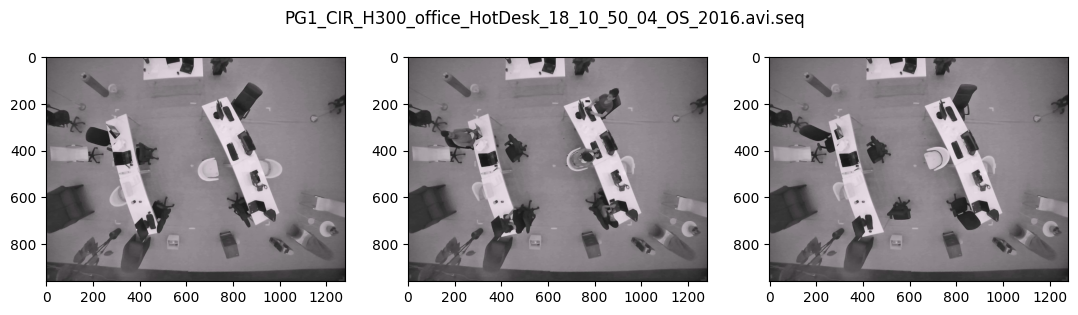

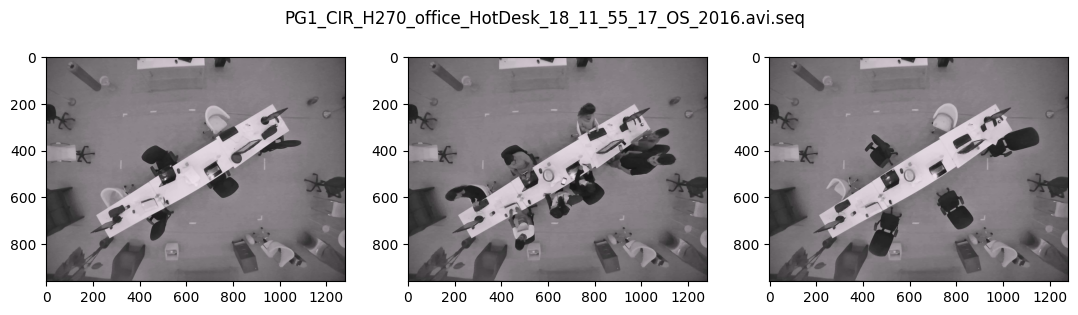

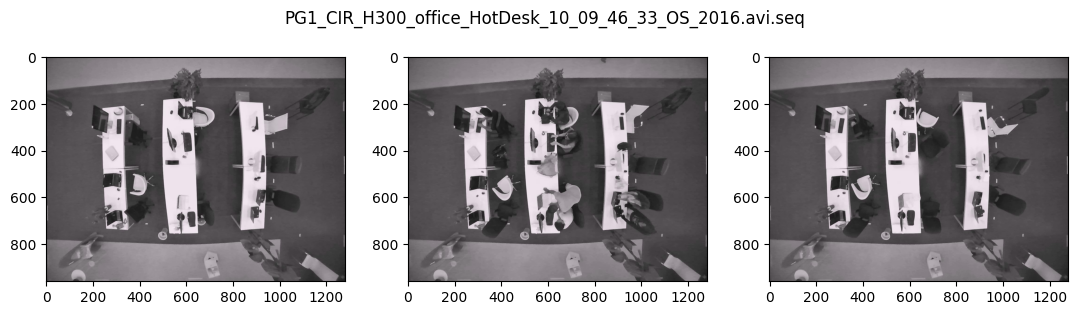

In [98]:
get_repsesentation(df, embedding_pths, clusters.labels_, 11)

In [17]:
get_repsesentation(df, embedding_pths, clusters.labels_, 12)

NameError: name 'df' is not defined

In [18]:
get_repsesentation(df, embedding_pths, cl_similar.labels_, 10)

NameError: name 'df' is not defined

In [19]:
get_repsesentation(df, embedding_pths, cl_similar.labels_, 21)

NameError: name 'df' is not defined

In [20]:
get_repsesentation(df, embedding_pths, cl_similar.labels_, 31)

NameError: name 'df' is not defined